In [1]:
from itertools import product
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl
from scipy.linalg import qr, svd, hankel
from tqdm import tqdm

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

No windowing system present. Using surfaceless platform
No config found!
No config found!


Available devices:
✅ (default) | NVIDIA A100-SXM4-40GB | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 16.0.6, 256 bits) | CPU | Vulkan | Mesa 24.0.0-devel (git-3ca1f35cbf) (LLVM 16.0.6)
❗ | NVIDIA A100-SXM4-40GB/PCIe/SSE2 | Unknown | OpenGL | 


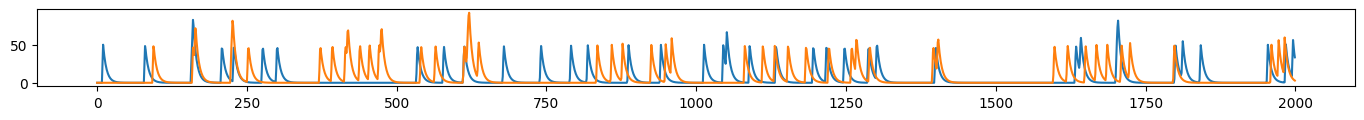

In [2]:
n_timepoints = 1_000
n_components = 2
interp_factor = 2

clean = np.zeros((n_components, n_timepoints * interp_factor))

x = 0
a = 0.7

b = 0

firing_prop = 0.05

spikes = list()

for i in range(n_components):
    spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(float))

for c_ix in range(n_components):
    for i in range(2, n_timepoints):
        clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2]) + (50 * spikes[c_ix][i])

    x_ = np.arange(0, n_timepoints * interp_factor)
    xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
    clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

n_timepoints *= 2

fig = plt.figure(figsize=(17, 1))
for i in range(n_components):
    plt.plot(clean[i])

In [3]:
noise = 5

In [23]:
n_pixels = 3

series = list()

for i in range(n_components):
    for j in range(n_pixels):
        series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))

series = np.vstack(series)
series[-1] = np.random.normal(scale=noise, size=n_timepoints)

In [24]:
series.shape

(6, 2000)

In [25]:
class SpaceTimeSVD:
    def __init__(self, movie_vectorized: np.ndarray, w: int):
        self.movie = movie_vectorized
        self.w = w
        self.adjacency = None

    def compute(self):
        print("Computing F, P")
        Ys = list()
        Ps = list()
        Fs = list()

        series = self.movie
        w = self.w

        n_pixels = self.movie.shape[0]
        for i in tqdm(range(n_pixels)):
            y = hankel(series[i, :w], series[i, w:])
            p = np.flipud(y[:int(w / 2)])
            f = y[int(w / 2):]
        
            Ys.append(y)
            Ps.append(p)
            Fs.append(f)

        P_F_shape = (int(w / 2) * n_pixels, n_timepoints - w)

        P = np.zeros(P_F_shape)
        F = np.zeros(P_F_shape)
        
        for i in tqdm(range(n_pixels)):
            P[i::n_pixels] = Ps[i]
            F[i::n_pixels] = Fs[i]

        print("computing H")
        H = (F @ P.T) / P.shape[1]

        print("Computing Hp")
        Hp = np.zeros((int(w / 2)**2, n_pixels**2))

        for row_ix, (block_i, block_j) in enumerate(product(*[range(0, int(w / 2) * n_pixels, n_pixels)]*2)):
            Hp[row_ix] = H.T[block_i:block_i + n_pixels, block_j:block_j + n_pixels].ravel()

        del H

        print("computimng svd of Hp")
        u, s, v = svd(Hp)

        del Hp

        self.adjacency = v[0].reshape(self.movie.shape[0], self.movie.shape[0])

In [26]:
class ClusteringCPQR:
    def __init__(self, adjacency: np.ndarray, k: int, truth_labels: np.ndarray):
        self.B = np.abs(adjacency + adjacency.T) / 2
        self.evals, self.evecs = np.linalg.eigh(self.B)

        self.vk = evecs[:, -k:]

        self.vkT = self.vk.T
        self.vkT /= np.linalg.norm(self.vkT, axis=0, ord=2)

        Q, R, self.pivots = qr(self.vkT, pivoting=True)
        
        u, s, vT = np.linalg.svd(self.vkT[:, self.pivots[:k]], full_matrices=False)
        self.U = u @ vT

        self.transformed = self.U.T @ self.vkT

In [27]:
st_svd = SpaceTimeSVD(series, w=16)
st_svd.compute()

Computing F, P


100%|██████████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:00<00:00, 18517.90it/s]

computing H
Computing Hp
computimng svd of Hp


<Axes: >

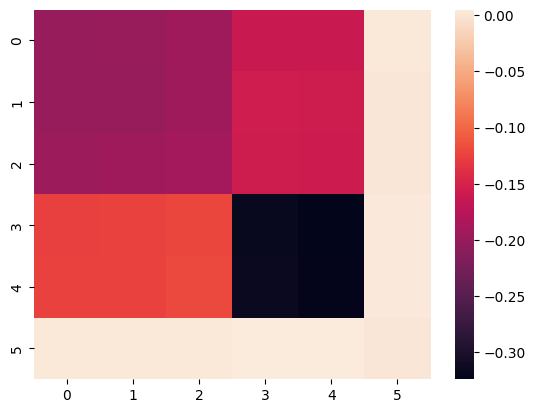

In [29]:
sns.heatmap(st_svd.adjacency)